# 1. Text processing, Language Modeling using RNN (LSTM/GRU).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.models import Model
from keras.layers import LSTM, Activation, Dense, Dropout, Input, Embedding
from keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.preprocessing import sequence
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping
%matplotlib inline

In [3]:
cd /content/drive/MyDrive/Colab Notebooks/Deep Learning

/content/drive/MyDrive/Colab Notebooks/Deep Learning


In [4]:
data = pd.read_csv('spam.csv',delimiter=',',encoding='latin-1')
data.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [5]:
data.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'],axis=1,inplace=True)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


Text(0.5, 0, 'Messages')

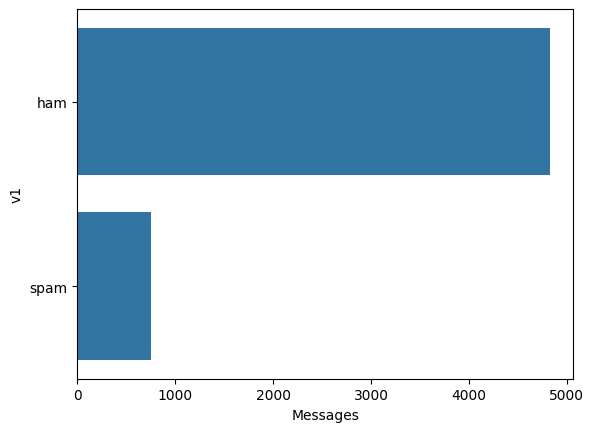

In [6]:
sns.countplot(data.v1)
plt.xlabel('Messages')

In [7]:
X = data.v2
Y = data.v1
le = LabelEncoder()
Y = le.fit_transform(Y)
Y = Y.reshape(-1,1)

In [8]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2)

In [9]:
max_words = 1000
max_len = 200
tok = Tokenizer(num_words=max_words)
tok.fit_on_texts(X_train)
sequences = tok.texts_to_sequences(X_train)
sequences_matrix = sequence.pad_sequences(sequences,maxlen=max_len)

In [10]:
def RNN():
    inputs = Input(name='inputs',shape=[max_len])
    layer = Embedding(max_words,50,input_length=max_len)(inputs)
    layer = LSTM(64)(layer)
    layer = Dense(256,name='FC1')(layer)
    layer = Activation('relu')(layer)
    layer = Dropout(0.5)(layer)
    layer = Dense(1,name='out_layer')(layer)
    layer = Activation('sigmoid')(layer)
    model = Model(inputs=inputs,outputs=layer)
    return model

In [11]:
model = RNN()
model.summary()
model.compile(loss='binary_crossentropy',optimizer=RMSprop(),metrics=['accuracy'])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ inputs (InputLayer)                  │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 200, 50)             │          50,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          29,440 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ FC1 (Dense)                          │ (None, 256)                 │          16,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ out_layer (Dense)                    │ (None, 1)                   │             257 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 1)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 96,337 (376.32 KB)

 Trainable params: 96,337 (376.32 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.fit(sequences_matrix,Y_train,batch_size=128,epochs=10,
          validation_split=0.2,callbacks=[EarlyStopping(monitor='val_loss',min_delta=0.0001)])

Epoch 1/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.8517 - loss: 0.4675 - val_accuracy: 0.8778 - val_loss: 0.2508
Epoch 2/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9409 - loss: 0.1882 - val_accuracy: 0.9731 - val_loss: 0.1282
Epoch 3/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9764 - loss: 0.0966 - val_accuracy: 0.9787 - val_loss: 0.0746
Epoch 4/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9841 - loss: 0.0618 - val_accuracy: 0.9753 - val_loss: 0.0798


In [13]:
test_sequences = tok.texts_to_sequences(X_test)
test_sequences_matrix = sequence.pad_sequences(test_sequences,maxlen=max_len)

In [14]:
acc = model.evaluate(test_sequences_matrix,Y_test)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9807 - loss: 0.0642


In [15]:
print('Test set\n  Loss: {:0.3f}\n  Accuracy: {:0.3f}'.format(acc[0],acc[1]))

Test set
  Loss: 0.070
  Accuracy: 0.982


# 2. Transfer Learning models for classification problems.

In [28]:
from transformers import BertTokenizer, TFBertModel
import tensorflow as tf
from sklearn.metrics import classification_report

In [29]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize_data(texts):
    return tokenizer(texts, padding='max_length', truncation=True, return_tensors='tf', max_length=max_len)

X_train_tokens = tokenize_data(X_train.tolist())
X_test_tokens = tokenize_data(X_test.tolist())

/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [30]:
bert_model = TFBertModel.from_pretrained('bert-base-uncased')

input_ids = tf.keras.Input(shape=(max_len,), dtype=tf.int32, name='input_ids')
attention_masks = tf.keras.Input(shape=(max_len,), dtype=tf.int32, name='attention_mask')

class BertLayer(tf.keras.layers.Layer):
    def __init__(self, bert_model):
        super(BertLayer, self).__init__()
        self.bert_model = bert_model

    def call(self, inputs, attention_mask=None):
        bert_outputs = self.bert_model(inputs, attention_mask=tf.cast(attention_mask, dtype=tf.int32))
        return bert_outputs.last_hidden_state[:, 0, :]

bert_layer = BertLayer(bert_model)

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.bias']
- This IS expected if you are initializing TFBertModel from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertModel from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
All the weights of TFBertModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertModel for predictions w

In [31]:
cls_token = bert_layer(input_ids, attention_mask=attention_masks)
dense = tf.keras.layers.Dense(64, activation='relu')(cls_token)
dropout = tf.keras.layers.Dropout(0.5)(dense)
output = tf.keras.layers.Dense(1, activation='sigmoid')(dropout)

model = tf.keras.Model(inputs=[input_ids, attention_masks], outputs=output)

In [32]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5), loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(
    [X_train_tokens['input_ids'], X_train_tokens['attention_mask']],
    Y_train,
    batch_size=128,
    epochs=5,
    validation_split=0.2,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2)]
)

Epoch 1/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 104s 3s/step - accuracy: 0.4540 - loss: 0.7522 - val_accuracy: 0.8094 - val_loss: 0.5917
Epoch 2/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.6932 - loss: 0.5865 - val_accuracy: 0.8498 - val_loss: 0.4924
Epoch 3/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.7982 - loss: 0.5063 - val_accuracy: 0.8543 - val_loss: 0.4344
Epoch 4/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.8446 - loss: 0.4438 - val_accuracy: 0.8554 - val_loss: 0.3986
Epoch 5/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.8568 - loss: 0.4093 - val_accuracy: 0.8554 - val_loss: 0.3748


In [33]:
predictions = model.predict([X_test_tokens['input_ids'], X_test_tokens['attention_mask']])
predictions = (predictions > 0.5).astype(int)

print(classification_report(Y_test, predictions))

35/35 ━━━━━━━━━━━━━━━━━━━━ 27s 593ms/step
              precision    recall  f1-score   support

           0       0.86      1.00      0.93       960
           1       0.00      0.00      0.00       155

    accuracy                           0.86      1115
   macro avg       0.43      0.50      0.46      1115
weighted avg       0.74      0.86      0.80      1115



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
